In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv('ML/uber.csv')

In [19]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 23.4 MB


In [21]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [22]:
df.drop(["Unnamed: 0", "key"], axis = 1, inplace = True)

In [23]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors="coerce", utc=True)

In [24]:
df.dropna(inplace=True)

In [25]:
df = df[df['fare_amount'] > 0]

In [26]:
df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)]

In [27]:
df = df[
    (df['pickup_longitude'].between(-74.5, -72.5)) &
    (df['dropoff_longitude'].between(-74.5, -72.5)) &
    (df['pickup_latitude'].between(40.0, 41.5)) &
    (df['dropoff_latitude'].between(40.0, 41.5))
]

In [28]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek

In [29]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


In [30]:
def distance(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat/2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2) ** 2)
    c = 2 * np.arcsin(np.sqrt(a))
    radius = 6371
    return radius * c

In [31]:
df['dist_km'] = distance(df['pickup_latitude'], df['pickup_longitude'], df['dropoff_latitude'], df['dropoff_longitude'])

In [32]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,dist_km
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


In [33]:
df = df[df['dist_km'] > 0]
df = df[df['dist_km'] < 100]

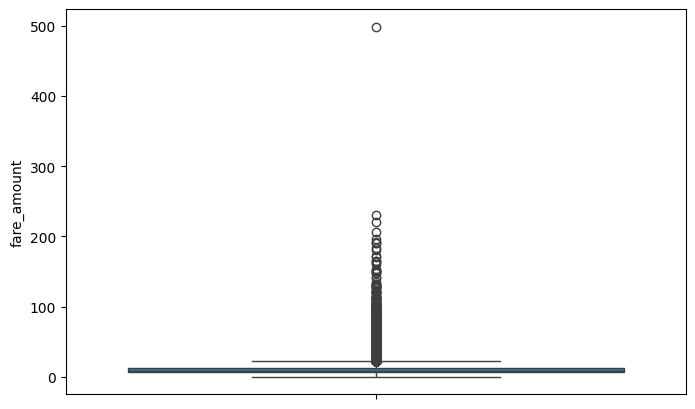

In [34]:
plt.figure(figsize=(8, 5))
sns.boxplot(y = df['fare_amount'])
plt.show()

In [35]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[
    (df['fare_amount'] >= lower_bound) &
    (df['fare_amount'] <= upper_bound)
]

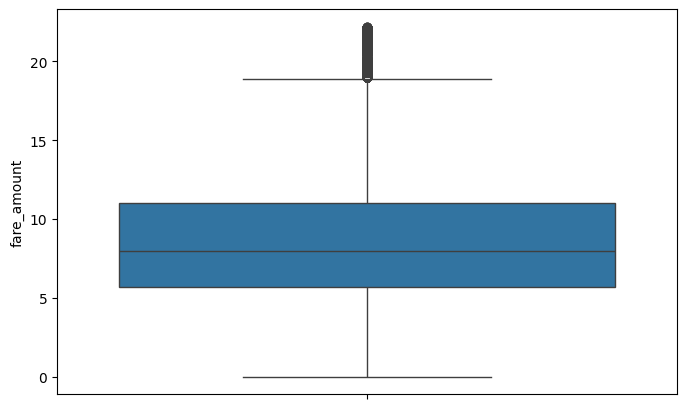

In [36]:
plt.figure(figsize=(8, 5))
sns.boxplot(y = df['fare_amount'])
plt.show()

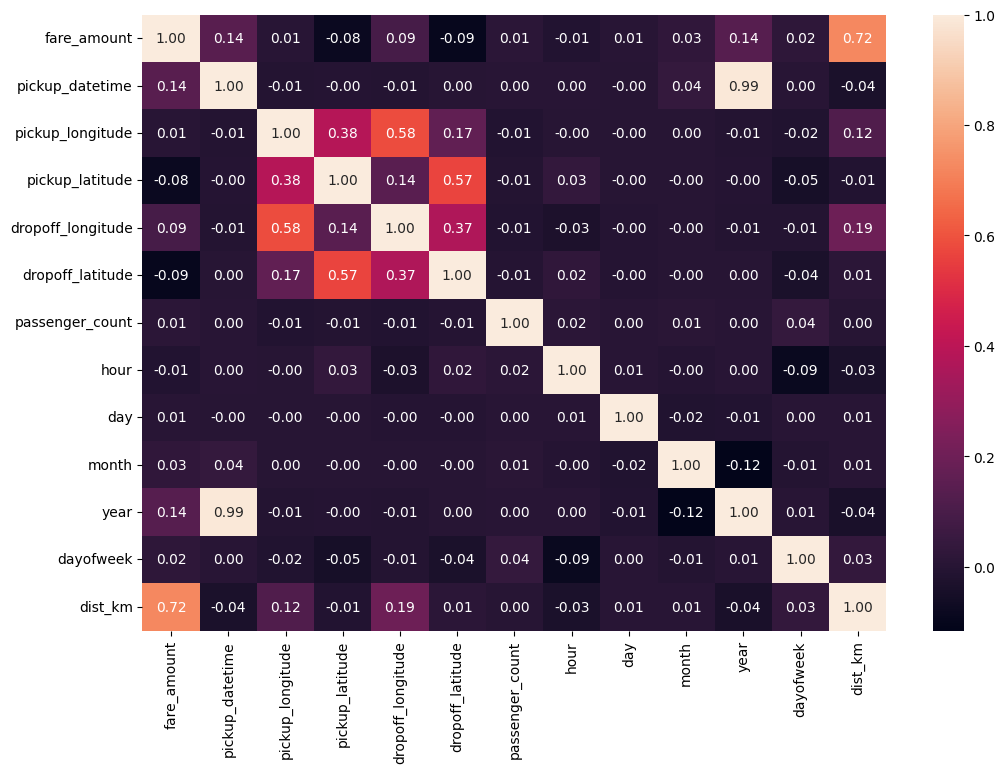

In [38]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f")
plt.show()

In [39]:
X = df.drop(['fare_amount', 'pickup_datetime'], axis=1)

In [40]:
y = df['fare_amount']

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [43]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

In [44]:
linear_r2 = r2_score(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_mae = mean_absolute_error(y_test, linear_pred)

In [45]:
random_forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=1)
random_forest.fit(X_train, y_train)
rf_pred = random_forest.predict(X_test)

In [46]:
random_forest_r2 = r2_score(y_test, rf_pred)
random_forest_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
random_forest_mae = mean_absolute_error(y_test, rf_pred)

In [47]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "R2 Score": [linear_r2, random_forest_r2],
    "RMSE": [linear_rmse, random_forest_rmse],
    "MAE": [linear_mae, random_forest_mae]
})

In [48]:
df = df.drop(['fare_amount'], axis=1)

In [51]:
df = df.drop(['pickup_datetime'], axis=1)

In [52]:
df.columns.tolist

<bound method IndexOpsMixin.tolist of Index(['pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count', 'hour', 'day', 'month', 'year',
       'dayofweek', 'dist_km'],
      dtype='str')>

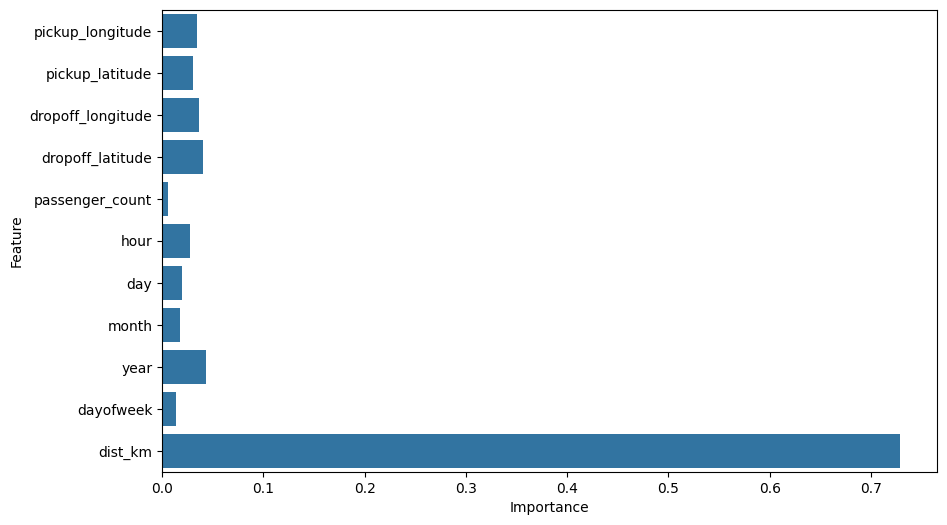

In [53]:
importance = pd.DataFrame({
    "Feature": df.columns,
    "Importance": random_forest.feature_importances_
})

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data = importance)
plt.show()

In [54]:
results

,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.558549,2.755397,1.764489
1,Random Forest Regression,0.781602,1.938060,1.327897
